<a href="https://colab.research.google.com/github/shuk95/GeneralProjects/blob/main/NIH_Disease_ML_Data_04292023Neil.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This code loads the data from the URL, selects the relevant features and target variable, encodes the target variable as numerical values, splits the data into training and testing sets, scales the features using StandardScaler, trains a logistic regression model, makes predictions on the test set and calculates the accuracy of the model. You can modify the machine learning algorithm, hyperparameters and features to improve the performance of the predictive bot

In [2]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, train_test_split
from keras import Sequential
from keras.layers import Input, Dense


In [3]:
# Load the data
data = pd.read_csv('https://ftp.ncbi.nlm.nih.gov/pub/clinvar/gene_condition_source_id', sep='\t')


In [4]:
# Remove unnecessary columns
data = data.drop(columns=['SourceName', 'SourceID', 'DiseaseMIM', 'LastUpdated'])


In [5]:
# Encode the target variable
le = LabelEncoder()
target = data['DiseaseName']
target = le.fit_transform(target)


In [6]:
# Encode the target variable
le = LabelEncoder()
target = data['DiseaseName']
target = le.fit_transform(target)


In [7]:
# Scale the numerical features
numerical_features = ['#GeneID']
scaler = StandardScaler()
# Create the features dataframe
df = pd.DataFrame(data)
print(df)
features = df.copy()
scaled_features = scaler.fit_transform(features[numerical_features])
features[numerical_features] = scaled_features

       #GeneID AssociatedGenes RelatedGenes ConceptID  \
0       144568           A2ML1          NaN  C1833692   
1        53947          A4GALT          NaN  C3549485   
2         8086            AAAS          NaN  C0271742   
3        79719           AAGAB          NaN  CN031225   
4           16           AARS1          NaN  C4225361   
...        ...             ...          ...       ...   
14308   130557             NaN       ZNF513  C0035334   
14309   130557             NaN       ZNF513  C0035334   
14310    22917             NaN          ZP1  CN238505   
14311     7783             NaN          ZP2  CN238505   
14312     7784             NaN          ZP3  CN238505   

                                          DiseaseName  
0                     Otitis media, susceptibility to  
1                            Blood group, P1PK system  
2            Glucocorticoid deficiency with achalasia  
3          Palmoplantar keratoderma, punctate type 1A  
4      Developmental and epileptic 

### Dataset Insights & Exploratory Data Analysis
Let's analyze the distribution of the dataset to see what genes and diseases are most prevalent in this ClinVar record.

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Number of unique genes and diseases
unique_genes = data['AssociatedGenes'].nunique()
unique_diseases = data['DiseaseName'].nunique()

print(f"Total Records: {len(data)}")
print(f"Unique Associated Genes: {unique_genes}")
print(f"Unique Diseases: {unique_diseases}")

Total Records: 14313
Unique Associated Genes: 5191
Unique Diseases: 7913


/tmp/ipykernel_1548/4224453475.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_genes.values, y=top_genes.index, palette='viridis')


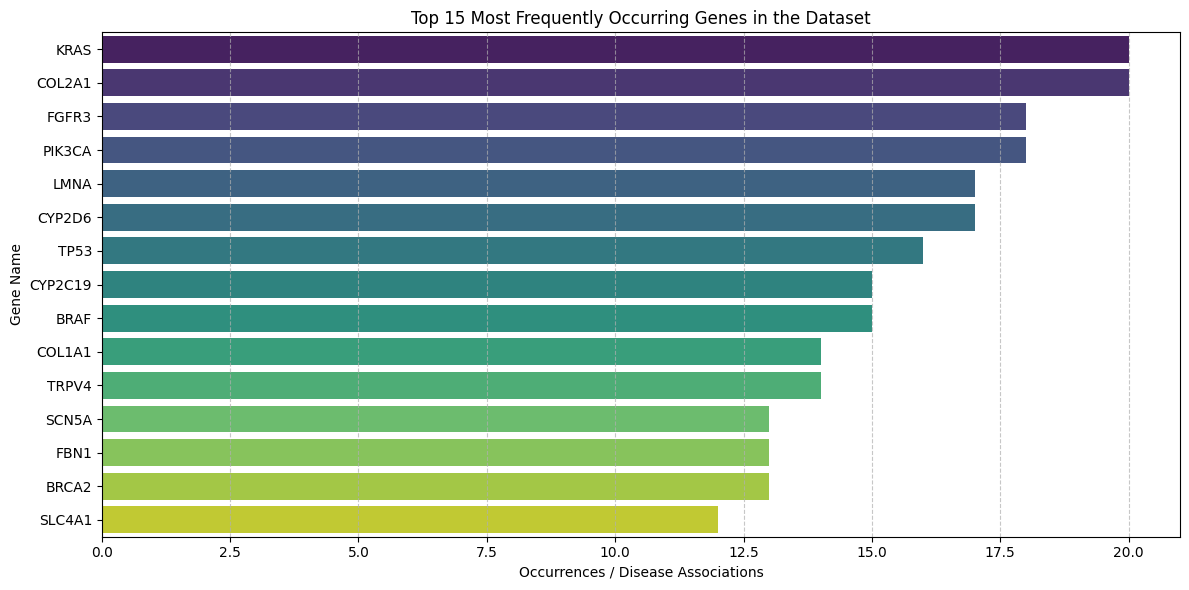

In [16]:
# 2. Top 15 Most Common Genes associated with diseases
top_genes = data['AssociatedGenes'].value_counts().head(15)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_genes.values, y=top_genes.index, palette='viridis')
plt.title('Top 15 Most Frequently Occurring Genes in the Dataset')
plt.xlabel('Occurrences / Disease Associations')
plt.ylabel('Gene Name')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

/tmp/ipykernel_1548/4053044676.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_diseases.values, y=top_diseases.index, palette='magma')


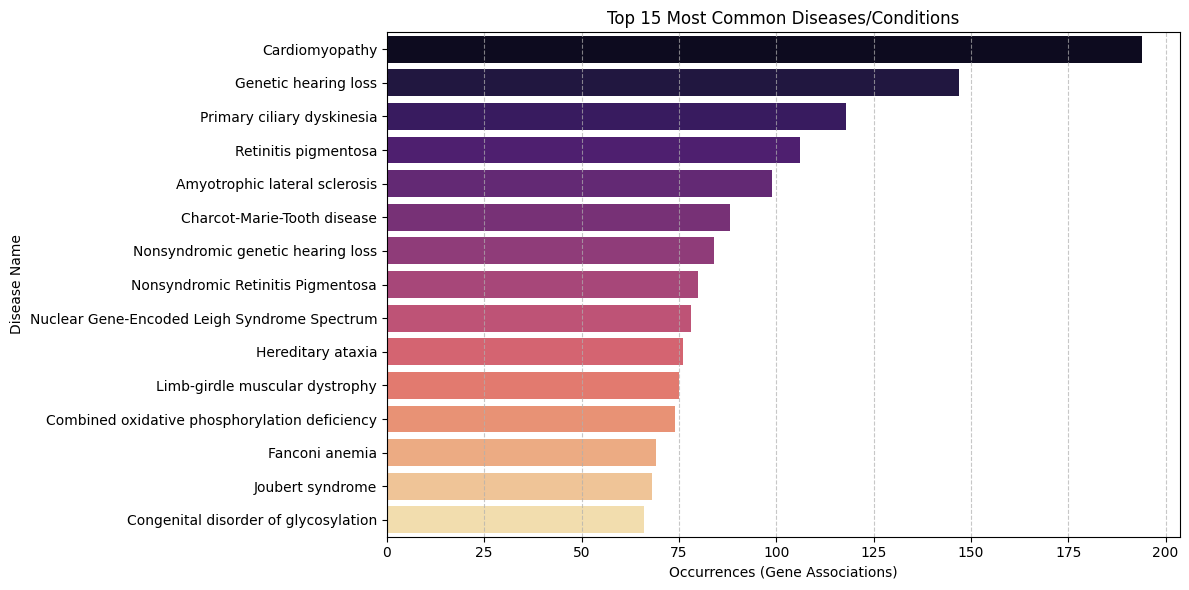

In [17]:
# 3. Top 15 Most Common Diseases
top_diseases = data['DiseaseName'].value_counts().head(15)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_diseases.values, y=top_diseases.index, palette='magma')
plt.title('Top 15 Most Common Diseases/Conditions')
plt.xlabel('Occurrences (Gene Associations)')
plt.ylabel('Disease Name')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Relu or Rectified Linear Activation Function is the most common choice of activation function in the world of deep learning

In [18]:
#Keep only numeric columns

X = features.select_dtypes(include=['number'])

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, target, test_size=0.2, random_state=42)

# Define the model correctly
model = Sequential([
    Input(shape=(X_train.shape[1],)),   # Define input shape explicitly
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(X_train, y_train, epochs=10, batch_size=32, validation_data=(X_test, y_test))

Epoch 1/10
358/358 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.0000e+00 - loss: -6453.7344 - val_accuracy: 6.9857e-04 - val_loss: -17995.4531
Epoch 2/10
358/358 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.0000e+00 - loss: -41449.7617 - val_accuracy: 6.9857e-04 - val_loss: -71065.8906
Epoch 3/10
358/358 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.0000e+00 - loss: -114931.0078 - val_accuracy: 6.9857e-04 - val_loss: -164237.8750
Epoch 4/10
358/358 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0000e+00 - loss: -225149.0469 - val_accuracy: 6.9857e-04 - val_loss: -291297.3438
Epoch 5/10
358/358 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.0000e+00 - loss: -370020.4688 - val_accuracy: 6.9857e-04 - val_loss: -453058.6250
Epoch 6/10
358/358 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.0000e+00 - loss: -549981.1250 - val_accuracy: 6.9857e-04 - val_loss: -649160.0000
Epoch 7/10
358/358 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0000e+00 - loss: -762954.1250 - val_accuracy: 6.985

In [19]:
# Scale the features
from keras import Sequential
from keras.layers import Input, Dense

model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')
])


In [20]:
# Feature selection
logreg = LogisticRegression(max_iter=1000)
rfe = RFE(estimator=logreg, n_features_to_select=5, step=1)


In [ ]:
# Hyperparameter tuning
parameters = {'penalty': ['l1', 'l2'], 'C': [0.001, 0.01, 0.1, 1, 10, 100, 1000]}
grid_search = GridSearchCV(estimator=logreg, param_grid=parameters, scoring='accuracy', cv=5)
grid_search = grid_search.fit(X_train, y_train)
best_parameters = grid_search.best_params_
best_score = grid_search.best_score_


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
